#GNSS Spoofing Demonstration

gps-sdr-sim is an open-source tool that synthesizes GPS L1 C/A baseband IQ samples. It computes, for
each simulated satellite in view, the correct code phase, Doppler, and navigation data bits for the specified
trajectory and time — then sums the individually spread satellite signals into a single output IQ file, exactly
mimicking what a real GPS front-end would digitize.


##Demonstrations Steps
**Step 1:** Obtain ephemeris: download a current broadcast ephemeris (RINEX .n / brdc file) for the current
date, e.g. from NASA CDDIS.

**Step 2:** Generate baseband IQ:
./gps-sdr-sim -e brdc2550.26n -l 22.496252,88.219964,100 -b 16 -s 2500000 -d 300 -o gpssim.bin

* -e ephemeris file
* -l static receiver latitude, longitude, height (meters)
* -b output bit depth (1/8/16-bit interleaved I/Q)
* -d simulation duration in seconds
* -o output IQ file

**Step 3:** Transmit via USRP:
/usr/bin/python3 gps-sdr-sim-uhd.py --args="addr=192.168.10.2" -f 1575420000 -s 2500000 -x 25 -t
gpssim.bin

* -f center transmit frequency in Hz
* -s sample rate (Hz)
* -x Transmitter gain in dB
* -t pre-generated baseband IQ samples

**Step 4:** Receive with GNSS-SDR
Receive the synthetic GNSS Signals. Run the following command in your terminal:

For USRP B210:

uhd_rx_cfile --args="type=b200" --freq=1575420000 --samp-rate=2500000 -g 50 -N 725000000 capture.dat

For USRP X310:

uhd_rx_cfile --args="addr=192.168.10.2" --freq=1575420000 --samp-rate=2500000 -g 50 -N 725000000
capture.dat

* --freq center receive frequency in Hz
* -samp-rate sample rate (Hz)
* -g reciever gain in dB
* -N number of samples = sample rate * time

##Analyze the signals using GNSS-SDR.

Run the following commands in the terminal.

```
cat > capture.conf << 'EOF'
; GNSS-SDR configuration for processing X310->B210 bench capture
[GNSS-SDR]
GNSS-SDR.internal_fs_sps=2500000
;######### SIGNAL_SOURCE CONFIG ############
SignalSource.implementation=File_Signal_Source
SignalSource.filename=/home/madhurima/Documents/tutorial/gps-sdr-sim/capture.dat
SignalSource.item_type=gr_complex
SignalSource.sampling_frequency=2500000
SignalSource.freq=1575420000
SignalSource.samples=0
SignalSource.repeat=false
SignalSource.enable_throttle_control=false
;######### SIGNAL_CONDITIONER CONFIG ############
SignalConditioner.implementation=Signal_Conditioner
DataTypeAdapter.implementation=Pass_Through
InputFilter.implementation=Pass_Through
InputFilter.input_item_type=gr_complex
InputFilter.output_item_type=gr_complex
Resampler.implementation=Pass_Through
Resampler.item_type=gr_complex
Resampler.sample_freq_in=2500000
Resampler.sample_freq_out=2500000
;######### CHANNELS GLOBAL CONFIG ############
Channels_1C.count=11
Channels.in_acquisition=1
Channel.signal=1C
;######### ACQUISITION GPS L1 CONFIG ############
Acquisition_1C.implementation=GPS_L1_CA_PCPS_Acquisition
Acquisition_1C.item_type=gr_complex
Acquisition_1C.coherent_integration_time_ms=1
Acquisition_1C.threshold=0.01
Acquisition_1C.doppler_max=5000
Acquisition_1C.doppler_step=250
Acquisition_1C.dump=false
;######### TRACKING GPS L1 CONFIG ############
Tracking_1C.implementation=GPS_L1_CA_DLL_PLL_Tracking
Tracking_1C.item_type=gr_complex
Tracking_1C.pll_bw_hz=40.0
Tracking_1C.dll_bw_hz=2.0
Tracking_1C.order=3
Tracking_1C.dump=true
Tracking_1C.dump_filename=./tracking_ch_
Tracking_1C.dump_mat=true
;######### TELEMETRY DECODER GPS CONFIG ############
TelemetryDecoder_1C.implementation=GPS_L1_CA_Telemetry_Decoder
TelemetryDecoder_1C.dump=false
;######### OBSERVABLES CONFIG ############
Observables.implementation=Hybrid_Observables
Observables.dump=true
Observables.dump_filename=./observables.dat
Observables.dump_mat=true
;######### PVT CONFIG ############
PVT.implementation=RTKLIB_PVT
PVT.positioning_mode=Single
PVT.iono_model=Broadcast
PVT.trop_model=Saastamoinen
PVT.output_rate_ms=1000
PVT.dump=true
PVT.dump_filename=./pvt.dat
PVT.dump_mat=true
EOF
gnss-sdr --config_file=capture.conf
```



# Analyzing spoofed GNSS signals

Loads GNSS-SDR `tracking_ch_*.mat` dumps, prints a CN0 summary table (best first), and plots the prompt I/Q constellation per channel and the carrier Doppler of all channels.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Folder with the GNSS-SDR dumps (searched recursively). Adjust if your Drive layout differs.
DATA_DIR = '/content/drive/MyDrive/LCIS Workshop data'

In [ ]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io as sio
import h5py

def load_mat(path):
    """Load a .mat file (v7.3/HDF5 or older) into a dict of flat numpy arrays."""
    try:
        d = sio.loadmat(path, squeeze_me=True)
        return {k: np.atleast_1d(v) for k, v in d.items() if not k.startswith('__')}
    except NotImplementedError:          # MATLAB v7.3 -> HDF5
        out = {}
        with h5py.File(path, 'r') as f:
            for k, v in f.items():
                if isinstance(v, h5py.Dataset) and v.dtype.kind in 'fiub':
                    out[k] = np.atleast_1d(np.squeeze(v[()]))
        return out

def getf(S, name):
    """Return the field as a 1-D array, or None if it doesn't exist / is empty."""
    v = S.get(name)
    if v is None or np.size(v) == 0:
        return None
    return np.asarray(v).ravel()

## Discover tracking dump files

In [ ]:
print(f'=== Scanning {DATA_DIR} for GNSS-SDR tracking dumps ===\n')
files = sorted(glob.glob(os.path.join(DATA_DIR, '**', 'tracking_ch_*.mat'), recursive=True))
if not files:
    print(f'No tracking_ch_*.mat files found in {DATA_DIR}')

track_data, track_labels = {}, {}
for fp in files:
    name = os.path.basename(fp)
    S = load_mat(fp)
    track_data[name] = S
    prn = getf(S, 'PRN')
    base = os.path.splitext(name)[0].replace('.dat', '')
    track_labels[name] = f'{base} (PRN {int(prn[0])})' if prn is not None else base
    print(f'[{name}] Fields: {", ".join(S.keys())}')

print(f'\nFound {len(files)} tracking file(s).')

=== Scanning /content/drive/MyDrive/LCIS Workshop data for GNSS-SDR tracking dumps ===

[tracking_ch_0.mat] Fields: CN0_SNV_dB_Hz, PRN, PRN_start_sample_count, Prompt_I, Prompt_Q, abs_E, abs_L, abs_P, abs_VE, abs_VL, acc_carrier_phase_rad, aux1, aux2, carr_error_filt_hz, carr_error_hz, carrier_doppler_hz, carrier_doppler_rate_hz, carrier_lock_test, code_error_chips, code_error_filt_chips, code_freq_chips, code_freq_rate_chips
[tracking_ch_1.mat] Fields: CN0_SNV_dB_Hz, PRN, PRN_start_sample_count, Prompt_I, Prompt_Q, abs_E, abs_L, abs_P, abs_VE, abs_VL, acc_carrier_phase_rad, aux1, aux2, carr_error_filt_hz, carr_error_hz, carrier_doppler_hz, carrier_doppler_rate_hz, carrier_lock_test, code_error_chips, code_error_filt_chips, code_freq_chips, code_freq_rate_chips
[tracking_ch_10.mat] Fields: CN0_SNV_dB_Hz, PRN, PRN_start_sample_count, Prompt_I, Prompt_Q, abs_E, abs_L, abs_P, abs_VE, abs_VL, acc_carrier_phase_rad, aux1, aux2, carr_error_filt_hz, carr_error_hz, carrier_doppler_hz, carrier_

## Output 1: CN0 summary table, sorted best-first

In [ ]:
rows = []
for name, S in track_data.items():
    cn0 = getf(S, 'CN0_SNV_dB_Hz')
    if cn0 is None:
        continue
    prn = getf(S, 'PRN')
    rows.append({'Channel': track_labels[name],
                 'PRN': int(prn[0]) if prn is not None else 'n/a',
                 'Mean CN0': np.mean(cn0),
                 'Std CN0': np.std(cn0, ddof=1)})   # ddof=1 matches MATLAB std
print('=== CN0 Summary (sorted by mean CN0, descending) ===')
if rows:
    df = pd.DataFrame(rows).sort_values('Mean CN0', ascending=False).reset_index(drop=True)
    display(df.style.format({'Mean CN0': '{:.2f}', 'Std CN0': '{:.2f}'}))
else:
    print('No CN0 data found in any tracking file.')

=== CN0 Summary (sorted by mean CN0, descending) ===


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:188: RuntimeWarning: invalid value encountered in subtract
  x = um.subtract(arr, arrmean, out=...)


,Channel,PRN,Mean CN0,Std CN0
0,tracking_ch_11 (PRN 23),23,52.20,2.84
1,tracking_ch_6 (PRN 18),18,48.13,2.21
2,tracking_ch_1 (PRN 13),13,48.10,2.73
3,tracking_ch_10 (PRN 22),22,43.30,8.87
4,tracking_ch_5 (PRN 17),17,43.14,12.44
5,tracking_ch_4 (PRN 16),16,40.64,10.43
6,tracking_ch_2 (PRN 14),14,31.02,3.73
7,tracking_ch_0 (PRN 1),1,31.00,3.79
8,tracking_ch_3 (PRN 15),15,31.00,3.79
9,tracking_ch_8 (PRN 20),20,30.91,3.73


## Output 2: Prompt I/Q constellation, one plot per channel

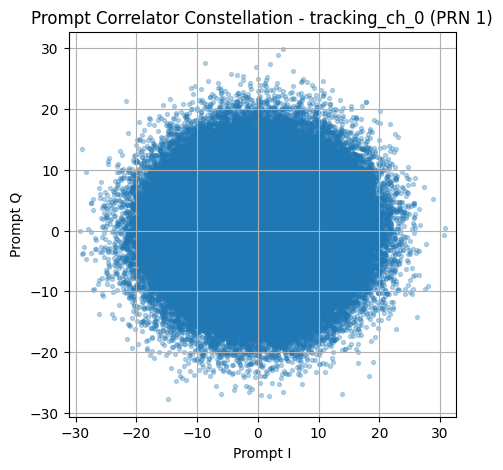

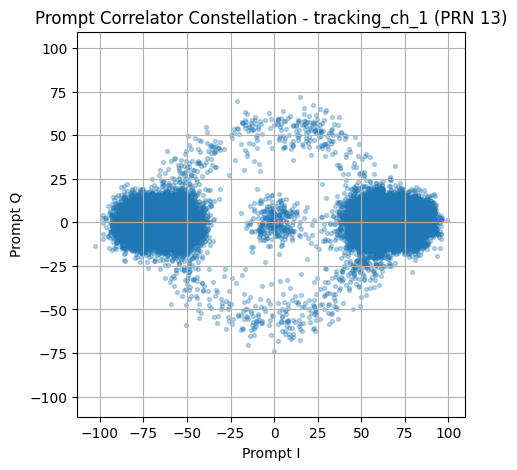

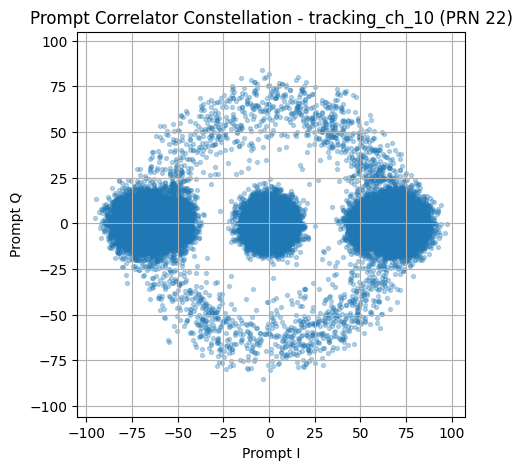

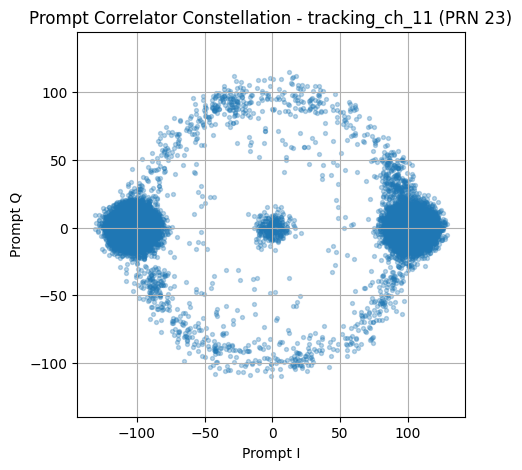

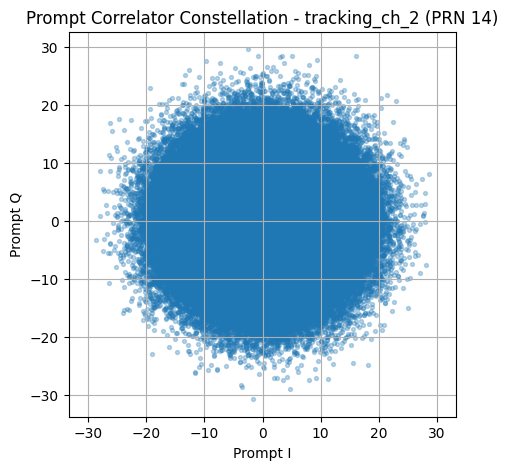

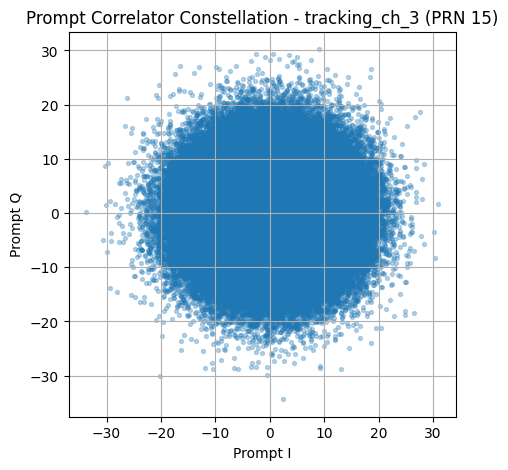

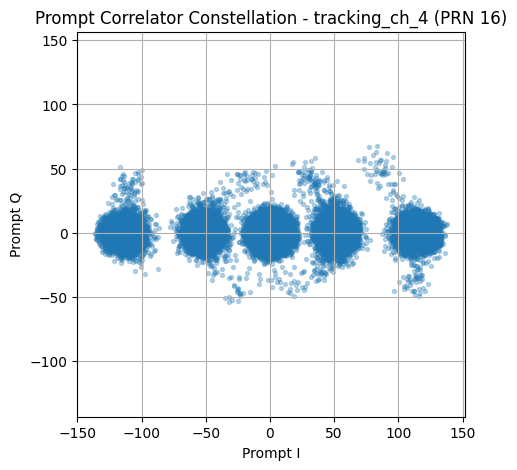

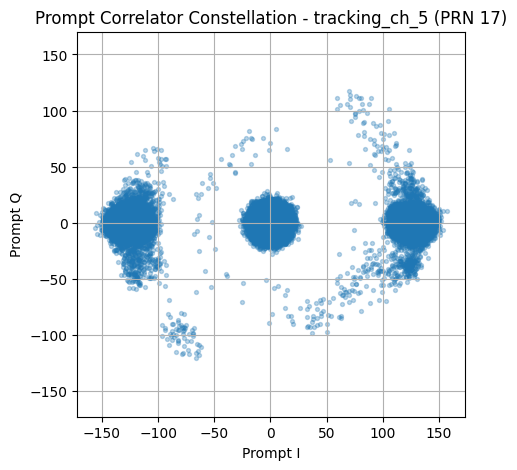

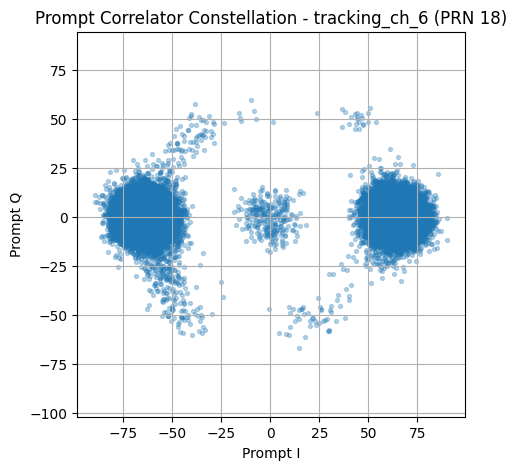

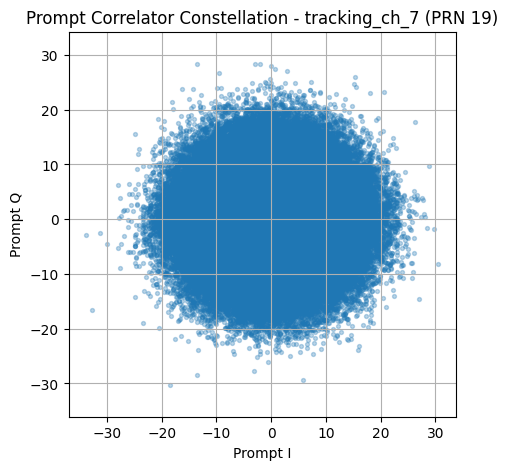

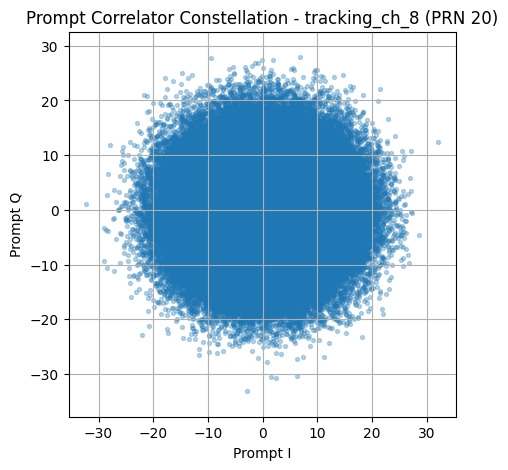

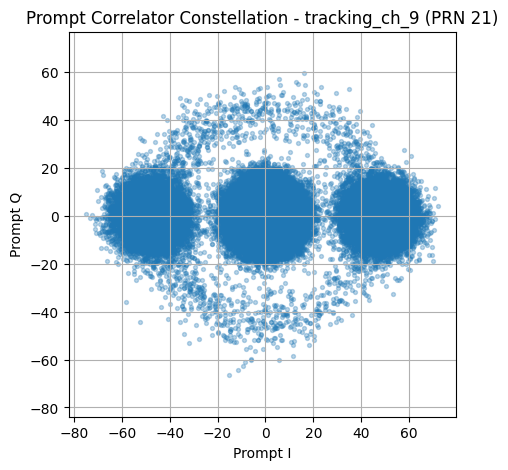

In [ ]:
for name, S in track_data.items():
    I, Q = getf(S, 'Prompt_I'), getf(S, 'Prompt_Q')
    if I is None or Q is None:
        print(f'No Prompt_I/Prompt_Q in {name}, skipping constellation.')
        continue
    plt.figure(figsize=(5, 5))
    plt.scatter(I, Q, s=8, alpha=0.3)
    plt.xlabel('Prompt I'); plt.ylabel('Prompt Q')
    plt.title(f'Prompt Correlator Constellation - {track_labels[name]}')
    plt.axis('equal'); plt.grid(True)
    plt.show()

## Output 3: Carrier Doppler vs time, all channels overlaid

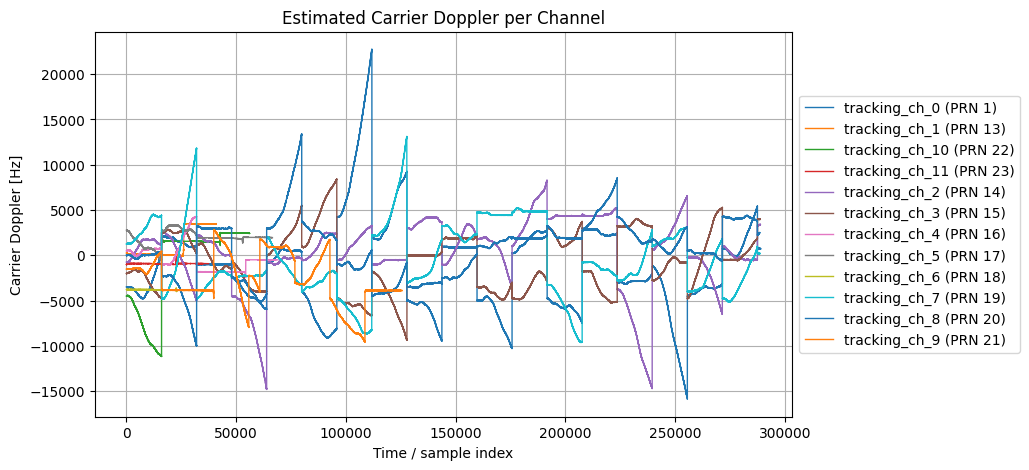


Done. Review the CN0 table and figures above.


In [ ]:
if track_data:
    plt.figure(figsize=(9, 5))
    plotted = False
    for name, S in track_data.items():
        dopp, t = getf(S, 'carrier_doppler_hz'), getf(S, 'RX_time')
        if dopp is None:
            print(f'No carrier_doppler_hz in {name}, skipping Doppler plot.')
            continue
        if t is None or len(t) != len(dopp):
            t = np.arange(1, len(dopp) + 1)
        plt.plot(t, dopp, lw=1.0, label=track_labels[name])
        plotted = True
    plt.xlabel('Time / sample index'); plt.ylabel('Carrier Doppler [Hz]')
    plt.title('Estimated Carrier Doppler per Channel')
    if plotted:
        plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.show()
print('\nDone. Review the CN0 table and figures above.')